# Análise longitudinal: a produção acadêmica sobre judicialização de medicamentos

Este notebook acompanha, ano a ano, os trabalhos que o Portal de Periódicos da CAPES devolve para "judicialização de medicamentos". Ele parte dos dados do script `examples/03_analise_temporal.py` e vai além da contagem anual: suaviza a série, mede o crescimento acumulado, compara períodos e acompanha a composição dos trabalhos ao longo do tempo.

**Fonte:** [Portal de Periódicos da CAPES](https://www.periodicos.capes.gov.br/index.php/acervo/buscador.html)

**Para rodar:** o notebook importa funções de `examples/`, então precisa de um clone do repositório e deve ser aberto de dentro da pasta `notebooks/`. No Google Colab, rode antes, numa célula: `!pip install git+https://github.com/bdcdo/raspe.git`, `!git clone https://github.com/bdcdo/raspe.git` e `%cd raspe/notebooks`. Os gráficos precisam do matplotlib (`pip install matplotlib`).

## Preparação

In [1]:
import importlib
import sys
from pathlib import Path

import pandas as pd

# A pasta examples/ fica ao lado de notebooks/. Incluí-la no caminho de importação deixa o
# notebook usar as funções do script sem copiá-las.
sys.path.insert(0, str(Path.cwd().parent / "examples"))

import matplotlib.pyplot as plt

# O nome do script começa com número, o que o comando import não aceita; importlib aceita.
temporal = importlib.import_module("03_analise_temporal")

## Os dados

Por padrão, o notebook lê a coleta que o script do exemplo 3 salvou em `examples/datasets/`, sem acessar a CAPES. Com `COLETAR_DE_NOVO = True`, ele refaz a coleta com a mesma função do script: até 21 requisições, cerca de um minuto. A releitura é o padrão porque o portal bloqueia por alguns minutos quem faz muitas requisições seguidas; em outubro de 2026, isso aconteceu depois de umas 25.

In [2]:
COLETAR_DE_NOVO = False

if COLETAR_DE_NOVO:
    publicacoes = temporal.coletar_publicacoes(temporal.TERMO)
else:
    arquivo = Path("..", "examples", "datasets", "03_capes_judicializacao_medicamentos.csv")
    publicacoes = pd.read_csv(arquivo, encoding="utf-8-sig", dtype={"ano": "Int64"})

print(f"{len(publicacoes)} trabalhos para {temporal.TERMO!r}")
publicacoes[["id", "tipo", "ano", "acesso_aberto", "doi"]].head()

355 trabalhos para 'judicialização de medicamentos'


,id,tipo,ano,acesso_aberto,doi
0,W4387665869,Artigo,2023,True,10.26432/1809-3019.2023.68.019
1,W2928245509,Artigo,2019,True,10.21450/rahis.v15i3.5156
2,W3154089213,Artigo,2021,False,10.29381/0103-8559/20213101127-33
3,W2996025548,Artigo,2019,True,10.21680/1982-310x.2019v12n1id17502
4,W4387330564,Artigo,2023,True,10.14295/jmphc.v15.1334


## A série anual

`contar_por_ano()` conta os trabalhos de cada ano e põe zero nos anos sem nenhum, para que um ano vazio não suma do eixo. A série começa no primeiro ano com trabalho e termina no último ano completo, `temporal.ANO_FINAL`.

A média móvel centrada de três anos troca cada ano pela média dele com o anterior e o seguinte. Ela tira o sobe e desce de um ano para o outro e deixa a tendência à vista. Por ser centrada, o primeiro e o último ano ficam sem valor.

In [3]:
ano_inicial = max(temporal.ANO_INICIAL, int(publicacoes["ano"].min()))
por_ano = temporal.contar_por_ano(publicacoes, ano_inicial, temporal.ANO_FINAL)
media_movel = por_ano.rolling(3, center=True).mean()

pd.DataFrame({"trabalhos": por_ano, "média móvel de 3 anos": media_movel.round(1)}).T

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
trabalhos,3,3,8,8,9,13,19,27,33,37,52,30,29,39,29,10
média móvel de 3 anos,NaN,4.7,6.3,8.3,10.0,13.7,19.7,26.3,32.3,40.7,39.7,37.0,32.7,32.3,26.0,NaN


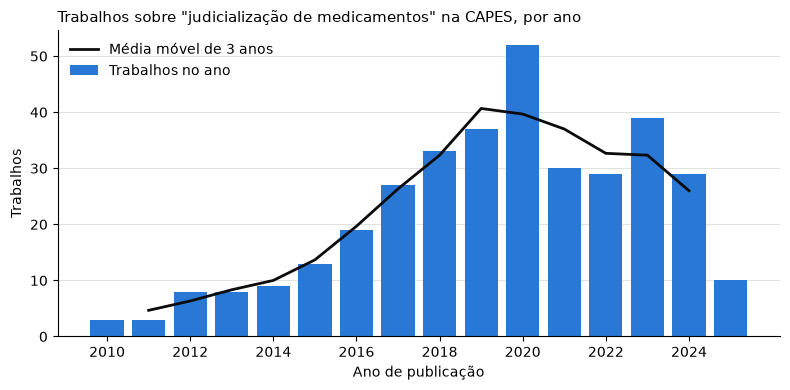

In [4]:
figura, eixo = plt.subplots(figsize=(8, 4), dpi=100)
eixo.bar(por_ano.index, por_ano.to_numpy(), color="#2a78d6", width=0.8, label="Trabalhos no ano")
eixo.plot(media_movel.index, media_movel.to_numpy(), color="#0b0b0b", linewidth=2, label="Média móvel de 3 anos")
eixo.set_title(f'Trabalhos sobre "{temporal.TERMO}" na CAPES, por ano', loc="left", fontsize=11)
eixo.set_xlabel("Ano de publicação")
eixo.set_ylabel("Trabalhos")
eixo.set_xticks(list(por_ano.index[::2]))
eixo.spines[["top", "right"]].set_visible(False)
eixo.grid(axis="y", color="#e2e1dd", linewidth=0.8)
eixo.set_axisbelow(True)
eixo.legend(frameon=False, loc="upper left")
figura.tight_layout()
plt.show()

## Crescimento acumulado

A fração acumulada diz que parte de toda a produção do período já tinha saído até cada ano. O ano em que ela passa de metade resume, num número só, quão recente é a literatura.

In [5]:
acumulado = por_ano.cumsum() / por_ano.sum()
ano_da_metade = int(acumulado[acumulado >= 0.5].index[0])
print(f"Metade dos {por_ano.sum()} trabalhos de {ano_inicial} a {temporal.ANO_FINAL} saiu até {ano_da_metade}.")

Metade dos 349 trabalhos de 2010 a 2025 saiu até 2020.


## Comparação de períodos

Um corte usado em estudos sobre judicialização da saúde é 2018, ano em que o Superior Tribunal de Justiça fixou, no Tema 106 dos recursos repetitivos, os requisitos para o poder público fornecer medicamento fora das listas do SUS. A tabela compara os cinco anos antes e os cinco anos depois do corte, sem o ano do corte. A comparação é descritiva: ela mostra se a produção mudou de patamar, não que o julgamento causou a mudança.

In [6]:
ANO_DE_CORTE = 2018

antes = por_ano.loc[ANO_DE_CORTE - 5 : ANO_DE_CORTE - 1]
depois = por_ano.loc[ANO_DE_CORTE + 1 : ANO_DE_CORTE + 5]
pd.DataFrame({
    "período": [f"{antes.index.min()} a {antes.index.max()}", f"{depois.index.min()} a {depois.index.max()}"],
    "trabalhos": [antes.sum(), depois.sum()],
    "média por ano": [round(antes.mean(), 1), round(depois.mean(), 1)],
})

,período,trabalhos,média por ano
0,2013 a 2017,76,15.2
1,2019 a 2023,187,37.4


## Composição ao longo do tempo

A contagem total pode crescer sem que a literatura mude de perfil, ou mudar de perfil sem crescer. Agrupar os anos em períodos e cruzar com outras colunas mostra a composição: o tipo de trabalho e a parcela em acesso aberto.

In [7]:
no_periodo = publicacoes[publicacoes["ano"].between(ano_inicial, temporal.ANO_FINAL)]
periodo = pd.cut(
    no_periodo["ano"].astype(int),
    bins=[ano_inicial - 1, 2014, 2019, temporal.ANO_FINAL],
    labels=[f"{ano_inicial} a 2014", "2015 a 2019", f"2020 a {temporal.ANO_FINAL}"],
).rename("período")

pd.crosstab(no_periodo["tipo"], periodo, margins=True, margins_name="Total")

período,2010 a 2014,2015 a 2019,2020 a 2025,Total
tipo,,,,
Artigo,30,128,189,347
Editorial,0,1,0,1
Revisão,1,0,0,1
Total,31,129,189,349


In [8]:
# Parcela, em %, dos trabalhos de cada período que o portal marca como acesso aberto.
(no_periodo.groupby(periodo, observed=True)["acesso_aberto"].mean() * 100).round(1).rename("% em acesso aberto")

período
2010 a 2014    96.8
2015 a 2019    92.2
2020 a 2025    96.3
Name: % em acesso aberto, dtype: float64

## Cuidados na leitura

- **Indexação atrasada.** O portal continua indexando trabalhos depois que eles saem, então os anos mais recentes tendem a crescer em coletas futuras. Uma queda no último ano completo pode ser, em parte, atraso de indexação.
- **O que a busca conta.** A série conta os trabalhos que o buscador associa ao termo, não todos os trabalhos sobre o tema. Outra formulação, como "judicialização da saúde", traz outra série.
- **Cobertura completa.** O portal ordena os resultados por relevância. Uma série temporal feita só com as primeiras páginas mediria a distribuição dos trabalhos mais relevantes, não da produção. Por isso o exemplo 3 coleta todas as páginas.